<a href="https://colab.research.google.com/github/2ec3/Deep-Generative-Models_Conditional-Diffusion/blob/main/TP3_3_Conditional_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3.3 — Guided Exercise: Training a Conditional Diffusion Model (CDM)

**Introduction to Deep Generative Models **

For each practical exercise (TP), please work in groups of two or three. Then, create a **private GitHub repository** and add me (my GitHub is **arthur-75**) to your project.

> This notebook transcribes the original PDF. Unfinished `xxx` placeholders and the original starter code have been retained. Use the previous DDPM exercises for the reused components.

This exercise extends the previous DDPM setup to include context-based training, allowing the model to generate samples conditioned on additional information, such as class labels or attributes. You will understand and implement Conditional Denoising Diffusion Models (CDDM).

## 1. Understanding Conditional Diffusion Models (CDM)

A Conditional Diffusion Model (CDM) extends DDPM by conditioning the model on additional information (e.g., class labels, textual descriptions, or other structured data). This enables controlled generation, where outputs are guided by specific attributes.

The denoising step in a conditional model is:

![Conditional diffusion denoising equation from the original handout](attachment:conditional_denoising_equation.png)

Where:
- `c` is contextual information (e.g., class labels).
- The model learns to remove noise conditioned on `c`.
- During training, a context-masking strategy is used, randomly ignoring context to ensure robustness.

## 2. Setup: Keeping the Same Components

For this exercise, we reuse the exact setup from the previous DDPM, ensuring consistency.

**Reused Components**

- Packages: Same PyTorch and utility imports.
- Network Hyperparameters: (e.g., feature dimensions, image size).
- Diffusion Hyperparameters: (e.g., number of timesteps, noise schedule).
- Training Hyperparameters: Learning rate, epochs, and batch size.
- DDPM Noise Schedule: Predefined beta schedule.
- Context U-Net Model: Supports conditional input.
- Denoising Function: `denoise_add_noise` remains the same.
- Dataset Handling: Uses `CustomDataset`.
- Perturbation Function: `perturb_input` remains unchanged.

*Use your setup from TP3.1 and TP3.2 before running the code below.*

In [1]:
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/DeepGenerativeModels

Mounted at /content/drive
/content/drive/MyDrive/DeepGenerativeModels


In [2]:
from tqdm import tqdm
import torch
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from diffusion_utilities import ResidualConvBlock, UnetUp, UnetDown, EmbedFC, plot_sample, CustomDataset, transform

# training hyperparameters
batch_size = 100
n_epoch = 32
lrate = 1e-3

# diffusion hyperparameters
timesteps = 500
beta1 = 1e-4
beta2 = 0.02

# network hyperparameters
device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
n_feat = 64  # 64 hidden dimension feature
n_cfeat = 5  # context vector is of size 5
height = 16  # 16x16 image

b_t = beta1 + (beta2 - beta1) * torch.linspace(0, 1, timesteps + 1, device=device)
a_t = 1 - b_t
ab_t = torch.cumsum(a_t.log(), dim=0).exp()
ab_t[0] = 1

In [3]:
class ContextUnet(nn.Module):
    def __init__(self, in_channels, n_feat=256, n_cfeat=10, height=28):  # cfeat - context features
        super(ContextUnet, self).__init__()

        # number of input channels, number of intermediate feature maps and number of classes
        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_cfeat = n_cfeat
        self.h = height  # assume h == w. must be divisible by 4, so 28,24,20,16...

        # Initialize the initial convolutional layer
        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        # Initialize the down-sampling path of the U-Net with two levels
        self.down1 = UnetDown(n_feat, n_feat)        # down1 #[10, 256, 8, 8]
        self.down2 = UnetDown(n_feat, 2 * n_feat)    # down2 #[10, 256, 4, 4]

        # original: self.to_vec = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        self.to_vec = nn.Sequential(nn.AvgPool2d((4)), nn.GELU())

        # Embed the timestep and context labels with a one-layer fully connected neural network
        self.timeembed1 = EmbedFC(1, 2*n_feat)
        self.timeembed2 = EmbedFC(1, 1*n_feat)
        self.contextembed1 = EmbedFC(n_cfeat, 2*n_feat)
        self.contextembed2 = EmbedFC(n_cfeat, 1*n_feat)

        # Initialize the up-sampling path of the U-Net with three levels
        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, self.h//4, self.h//4),  # up-sample
            nn.GroupNorm(8, 2 * n_feat),  # normalize
            nn.ReLU(),
        )
        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        # Initialize the final convolutional layers to map to same number of channels as input
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1),  # reduce number of feature maps
            nn.GroupNorm(8, n_feat),  # normalize
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1),  # map to same number of channels as input
        )

    def forward(self, x, t, c=None):
        """
        x : (batch, n_feat, h, w) : input image
        t : (batch, n_cfeat) : time step
        c : (batch, n_classes) : context label
        """
        # x is the input image, c is the context label, t is the timestep,
        # context_mask says which samples to block the context on
        x = self.init_conv(x)
        down1 = self.down1(x)          #[10, 256, 8, 8]
        down2 = self.down2(down1)      #[10, 256, 4, 4]
        hiddenvec = self.to_vec(down2)

        # mask out context if context_mask == 1
        if c is None:
            c = torch.zeros(x.shape[0], self.n_cfeat).to(x)

        # embed context and timestep
        cemb1 = self.contextembed1(c).view(-1, self.n_feat * 2, 1, 1)
        temb1 = self.timeembed1(t).view(-1, self.n_feat * 2, 1, 1)
        cemb2 = self.contextembed2(c).view(-1, self.n_feat, 1, 1)
        temb2 = self.timeembed2(t).view(-1, self.n_feat, 1, 1)

        up1 = self.up0(hiddenvec)
        up2 = self.up1(cemb1*up1 + temb1, down2)
        up3 = self.up2(cemb2*up2 + temb2, down1)
        out = self.out(torch.cat((up3, x), 1))
        return out

# construct model
nn_model = ContextUnet(in_channels=3, n_feat=n_feat, n_cfeat=n_cfeat, height=height).to(device)

In [4]:
# helper function; removes the predicted noise (but adds some noise back in to avoid collapse)
def denoise_add_noise(x, t, pred_noise, z=None):
    if z is None:
        z = torch.randn_like(x)
    noise = b_t.sqrt()[t] * z
    mean = (x - pred_noise * ((1 - a_t[t]) / (1 - ab_t[t]).sqrt())) / a_t[t].sqrt()
    return mean + noise

sprite shape: (89400, 16, 16, 3)
labels shape: (89400, 5)


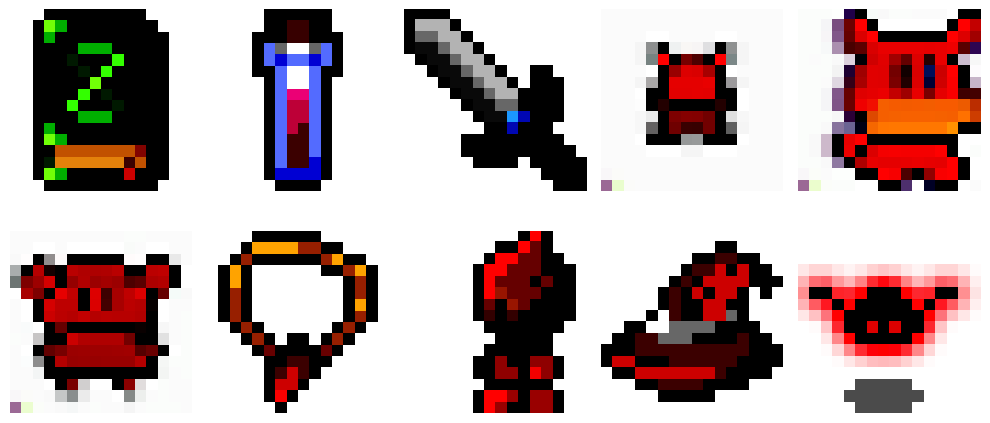

In [7]:
save_dir = "models_training/"

# load dataset and construct optimizer
dataset = CustomDataset("data/sprites_1788_16x16.npy",
                        "data/sprite_labels_nc_1788_16x16.npy", transform, null_context=False)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=1)
optim = torch.optim.Adam(nn_model.parameters(), lr=lrate)

def plot_sample_images(loader):
    images, _ = next(iter(loader))
    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].permute(1, 2, 0).cpu().numpy())
        plt.axis("off")
    plt.tight_layout()
    plt.show()
plot_sample_images(dataloader)

In [8]:
# helper function: perturbs an image to a specified noise level
def perturb_input(x, t, noise):
    return ab_t.sqrt()[t, None, None, None] * x + (1 - ab_t[t, None, None, None]) * noise

## 3. Training a Conditional Diffusion Model

- Incorporating Context (`c`) into Training
- Randomly Masking Context (to prevent over-reliance)
- Updating the Loss Function (same as DDPM but conditioned on context)

**Implementation Steps**

1. Enable Training Mode.
2. Decay Learning Rate Linearly Over Epochs.
3. Loop Through Batches: extract images (`x`) and context (`c`), and convert them to the correct device (GPU/CPU).
4. Randomly Mask Out Context: apply Bernoulli masking to randomly nullify `c` with 90% probability (as described in the source).
5. Apply Noise to Input Images (`perturb_input`).
6. Train the U-Net to Predict Noise Given Context.
7. Compute Mean Squared Error Loss and Update Weights.
8. Save Model Periodically.

In [13]:
# training with context code
# set into train mode
nn_model.train()

for ep in range(n_epoch):
    print(f'epoch {ep}')

    # linearly decay learning rate
    optim.param_groups[0]['lr'] = lrate*(1-ep/n_epoch)

    pbar = tqdm(dataloader, mininterval=2 )
    for x, c in pbar:   # x: images  c: context
        optim.zero_grad()
        x = x.to(device)
        c = c.to(device)

        # randomly mask out c
        context_mask = torch.bernoulli(torch.zeros(c.shape[0]) + 0.9).to(device)
        c = c * context_mask.unsqueeze(-1)

        # perturb data
        noise = torch.randn_like(x)
        t = torch.randint(1, timesteps + 1, (x.shape[0],)).to(device)
        x_pert = perturb_input(x, t, noise)

        # use network to recover noise
        pred_noise = nn_model(x_pert, t / timesteps, c=c)

        # loss is mean squared error between the predicted and true noise
        loss = F.mse_loss(pred_noise, noise)
        loss.backward()
        optim.step()

    # save model periodically
    if ep%4==0 or ep == int(n_epoch-1):
        if not os.path.exists(save_dir):
            os.mkdir(save_dir)
        torch.save(nn_model.state_dict(), save_dir + f"context_model_{ep}.pth")
        print('saved model at ' + save_dir + f"context_model_{ep}.pth")

epoch 0


100%|██████████| 894/894 [00:29<00:00, 30.51it/s]


saved model at models_training/context_model_0.pth
epoch 1


100%|██████████| 894/894 [00:28<00:00, 31.60it/s]


epoch 2


100%|██████████| 894/894 [00:27<00:00, 31.97it/s]


... (55 outputs left out)

100%|██████████| 894/894 [00:28<00:00, 31.01it/s]


epoch 31


100%|██████████| 894/894 [00:29<00:00, 30.30it/s]

saved model at models_training/context_model_31.pth


## 4. Sampling with Context

After training, we generate context-conditioned samples.

1. Load Pretrained Model and Set to Evaluation Mode.
2. Sample noise $x_T \sim \mathcal{N}(0,I)$.
3. Iteratively Remove Noise, Conditioned on Context.
4. Generate Samples and Visualize Them.

In [14]:
# sample with context using standard algorithm
@torch.no_grad()
def sample_ddpm_context(n_sample, context, save_rate=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    for i in range(timesteps, 0, -1):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        # sample some random noise to inject back in. For i = 1, don't add back in noise
        z = torch.randn_like(samples) if i > 1 else 0

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t, ctx)
        samples = denoise_add_noise(samples, i, eps, z)
        if i % save_rate==0 or i==timesteps or i<8:
            intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

## 5. Visualizing Context-Conditioned Samples

### Random Context Selection

In [15]:
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddpm_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate, 32, 4, save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

<Figure size 640x480 with 0 Axes>

### Custom Context (User Defined)

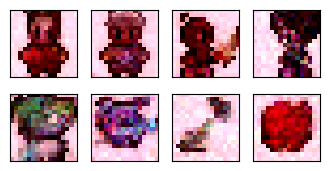

In [16]:
def show_images(imgs, nrow=2):
    _, axs = plt.subplots(nrow, imgs.shape[0] // nrow, figsize=(4,2 ))
    axs = axs.flatten()
    for img, ax in zip(imgs, axs):
        img = (img.permute(1, 2, 0).clone().clip(-1, 1).detach().cpu().numpy() +1) / 2
        ax.set_xticks([])
        ax.set_yticks([])
        ax.imshow(img)
    plt.show()

ctx = torch.tensor([
    [1,0,0,0,0],  # Hero
    [1,0,0,0,0],
    [0,0,0,0,1],  # Side-facing
    [0,0,0,0,1],
    [0,1,0,0,0],  # Non-hero
    [0,1,0,0,0],
    [0,0,1,0,0],  # Food
    [0,0,1,0,0],
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

### Blending Multiple Contexts

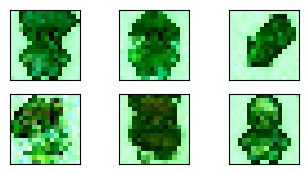

In [17]:
ctx = torch.tensor([
    [1,0,0,0,0],  # Human
    [1,0,0.6,0,0],
    [0,0,0.6,0.4,0],
    [1,0,0,0,1],
    [1,1,0,0,0],
    [1,0,0,1,0]
]).float().to(device)
samples, _ = sample_ddpm_context(ctx.shape[0], ctx)
show_images(samples)

## 4. DDIM with Context

Use the same `denoise_ddim` to plot.

*Section numbering retained from the original document.*

In [18]:
def denoise_ddim(x, t, t_prev, pred_noise):
   ab = ab_t[t]
   ab_prev = ab_t[t_prev]

   x0_pred = ab_prev.sqrt() / ab.sqrt() * (x - (1 - ab).sqrt() * pred_noise)
   dir_xt = (1 - ab_prev).sqrt() * pred_noise

   return x0_pred + dir_xt

In [19]:
# fast sampling algorithm with context
@torch.no_grad()
def sample_ddim_context(n_sample, context, n=20):
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 3, height, height).to(device)

    # array to keep track of generated steps for plotting
    intermediate = []
    step_size = timesteps // n
    for i in range(timesteps, 0, -step_size):
        print(f'sampling timestep {i:3d}', end='\r')

        # reshape time tensor
        t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

        eps = nn_model(samples, t, c=context)    # predict noise e_(x_t,t)
        samples = denoise_ddim(samples, i, i - step_size, eps)
        intermediate.append(samples.detach().cpu().numpy())

    intermediate = np.stack(intermediate)
    return samples, intermediate

# visualize samples
plt.clf()
ctx = F.one_hot(torch.randint(0, 5, (32,)), 5).to(device=device).float()
samples, intermediate = sample_ddim_context(32, ctx)
animation_ddpm_context = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddpm_context.to_jshtml())

<Figure size 640x480 with 0 Axes>

## Questions

1. Write the DDPM and DDIM equations and how do they work?
2. What is the difference between DDPM and DDIM? What is the advantage of each?

**Your answers:**

<!-- Write your answers here. -->

1. <br>
DDPM: $x_{t - 1} = \frac{1}{\sqrt{\alpha_t}}(x_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}}\varepsilon_t) + \sqrt{\beta_t}z$ <br>
DDPM denoise step by step, and each time add a new noise. <br>
DDIM: $x_{t - i} = \frac{\sqrt{\bar{\alpha}_{t - i}}}{\sqrt{\bar{\alpha}_t}}(x_t - \sqrt{1 - \bar{\alpha}_{t}}\varepsilon_t) + \sqrt{1 - \bar{\alpha}_{t - i}}\varepsilon_t$ <br>
DDIM can denoise by skiping steps, and it is deterministique. <br>
2. DDPM is stochastique and DDIM is deterministique; DDPM has better result, but is slower, while DDIM can skip steps but have slightly lower result.